In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("winequality-red.csv", sep=";")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [2]:
# Check dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Check wine quality distribution
print("\nWine Quality Counts:")
print(df["quality"].value_counts().sort_index())

# Statistical summary
display(df.describe())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

Missing Values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar       

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [3]:
# Remove duplicate rows
print("Rows before cleaning:", df.shape[0])

df = df.drop_duplicates().reset_index(drop=True)

print("Rows after cleaning:", df.shape[0])
print("Duplicate rows remaining:", df.duplicated().sum())
print("Missing values remaining:", df.isnull().sum().sum())

# Check quality distribution after cleaning
print("\nWine Quality Distribution:")
print(df["quality"].value_counts().sort_index())

Rows before cleaning: 1599
Rows after cleaning: 1359
Duplicate rows remaining: 0
Missing values remaining: 0

Wine Quality Distribution:
quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


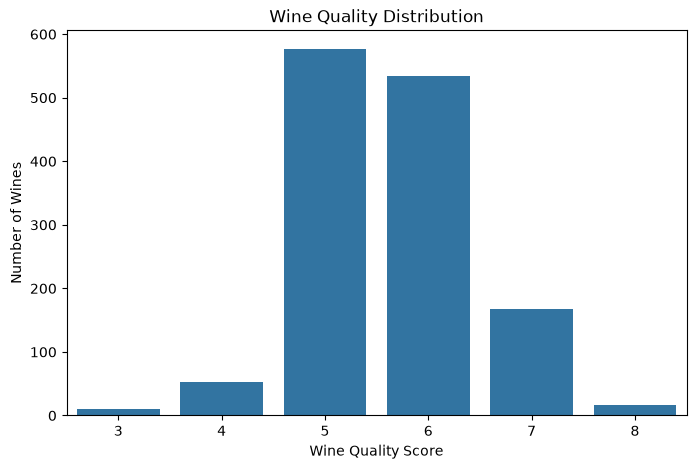

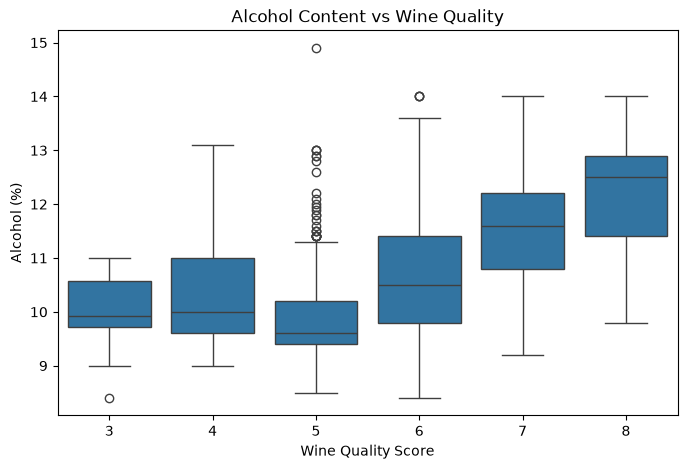

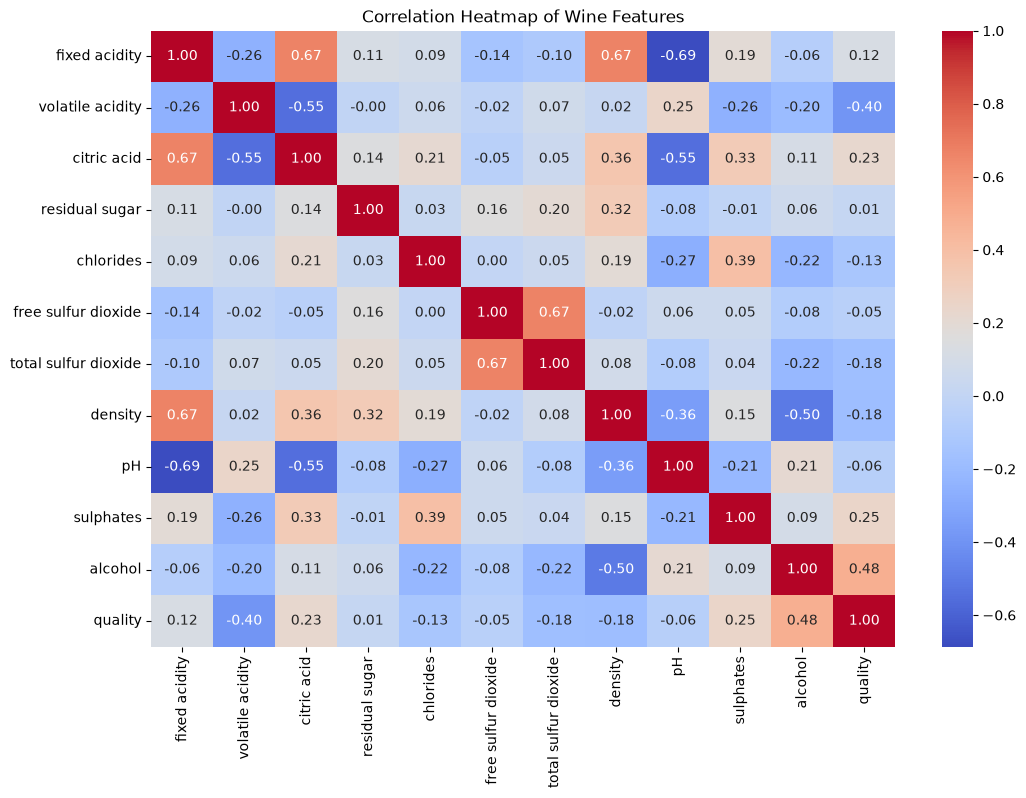

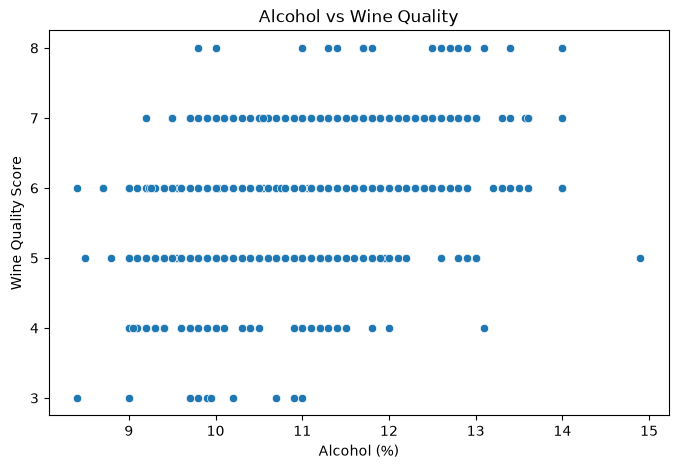

In [4]:
# 1. Wine Quality Distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="quality")
plt.title("Wine Quality Distribution")
plt.xlabel("Wine Quality Score")
plt.ylabel("Number of Wines")
plt.show()

# 2. Alcohol vs Wine Quality
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="quality", y="alcohol")
plt.title("Alcohol Content vs Wine Quality")
plt.xlabel("Wine Quality Score")
plt.ylabel("Alcohol (%)")
plt.show()

# 3. Correlation Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Wine Features")
plt.show()

# 4. Alcohol vs Quality
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="alcohol", y="quality")
plt.title("Alcohol vs Wine Quality")
plt.xlabel("Alcohol (%)")
plt.ylabel("Wine Quality Score")
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

# Features and target
X = df.drop("quality", axis=1)
y = df["quality"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Model 1: Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

# Model 2: Logistic Regression
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, class_weight="balanced")
)
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

# Evaluate models
print("Random Forest Accuracy:",
      round(accuracy_score(y_test, rf_pred) * 100, 2), "%")

print("\nRandom Forest Classification Report:")
print(classification_report(y_test, rf_pred, zero_division=0))

print("\nLogistic Regression Accuracy:",
      round(accuracy_score(y_test, lr_pred) * 100, 2), "%")

print("\nLogistic Regression Classification Report:")
print(classification_report(y_test, lr_pred, zero_division=0))

Random Forest Accuracy: 58.09 %

Random Forest Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.12      0.09      0.11        11
           5       0.68      0.72      0.70       116
           6       0.58      0.50      0.54       107
           7       0.42      0.58      0.49        33
           8       0.00      0.00      0.00         3

    accuracy                           0.58       272
   macro avg       0.30      0.32      0.31       272
weighted avg       0.58      0.58      0.58       272


Logistic Regression Accuracy: 41.91 %

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.07      0.27      0.11        11
           5       0.71      0.57      0.63       116
           6       0.52      0.27      0.36       107
           7       0.34      0.48

,Model,Accuracy (%)
0,Random Forest,58.09
1,Logistic Regression,41.91


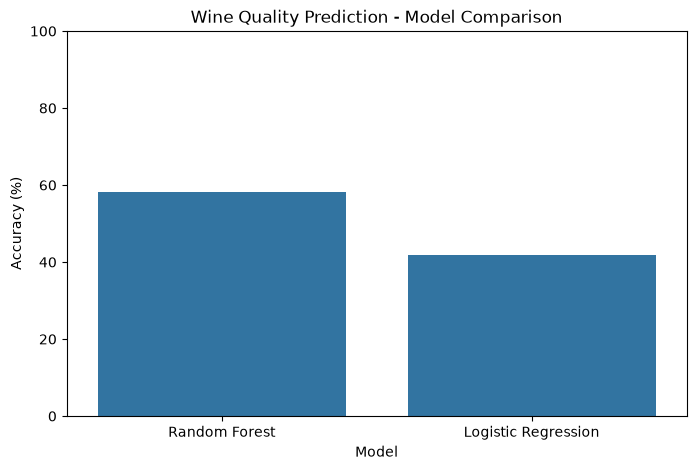

Model comparison saved successfully!


In [6]:
# Compare model performance
results = pd.DataFrame({
    "Model": ["Random Forest", "Logistic Regression"],
    "Accuracy (%)": [
        accuracy_score(y_test, rf_pred) * 100,
        accuracy_score(y_test, lr_pred) * 100
    ]
})

display(results.round(2))

# Plot comparison
plt.figure(figsize=(8, 5))
sns.barplot(data=results, x="Model", y="Accuracy (%)")
plt.title("Wine Quality Prediction - Model Comparison")
plt.ylim(0, 100)
plt.ylabel("Accuracy (%)")
plt.show()

# Save results
results.round(2).to_csv("model_comparison.csv", index=False)
print("Model comparison saved successfully!")

,Feature,Importance
10,alcohol,0.1398
9,sulphates,0.1288
1,volatile acidity,0.1285
7,density,0.0888
6,total sulfur dioxide,0.0877
2,citric acid,0.0801
4,chlorides,0.0762
8,pH,0.0752
0,fixed acidity,0.0681
5,free sulfur dioxide,0.0653


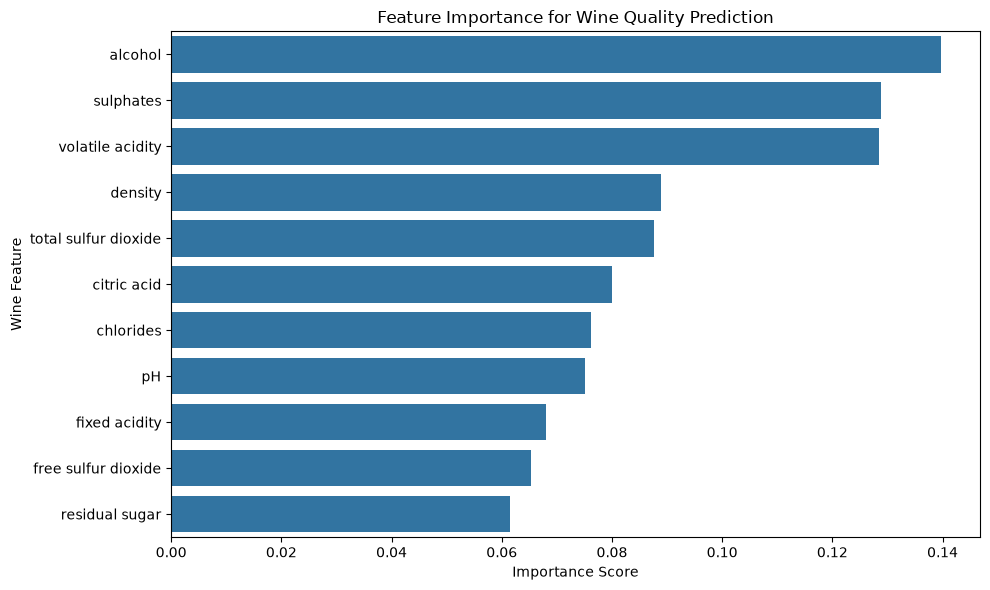

In [7]:
# Feature importance from Random Forest
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance", ascending=False
)

display(importance.round(4))

plt.figure(figsize=(10, 6))
sns.barplot(data=importance, x="Importance", y="Feature")
plt.title("Feature Importance for Wine Quality Prediction")
plt.xlabel("Importance Score")
plt.ylabel("Wine Feature")
plt.tight_layout()
plt.show()